In [122]:
import pandas as pd

In [123]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train (7).csv


In [124]:
df = pd.read_csv('train.csv')

In [125]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [126]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [127]:
#preprocessing
df = df.drop(columns = ['PassengerId','Name','Ticket','Cabin','Sex','Embarked'])

In [128]:
#check for null values in the columns, as when training, logistic regression can't deal with null values!
print(df.isnull().sum())

Survived      0
Pclass        0
Age         177
SibSp         0
Parch         0
Fare          0
dtype: int64


this tells us that the age column has 177 null values. We can either delete those rows or assign them a value.

In [129]:
# Fill missing Age values with the median
df['Age'] =df['Age'].fillna(df['Age'].median())
#other way was to delete those 177 rows, but that would cause loss of data from the training set, so i have avoided it.If you want to delete it:
#df.dropna(inplace=True)
#this removes rows with any missing values

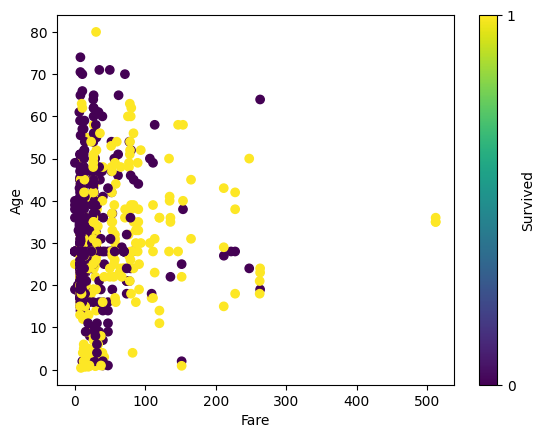

In [130]:
#EDA
import matplotlib.pyplot as plt
plt.scatter(df['Fare'],df['Age'],c=df['Survived'])
plt.xlabel('Fare')
plt.ylabel('Age')
plt.colorbar(ticks = [0,1], label = 'Survived')
plt.show()

here yellow(1) means survived and blue means did not survive(0).

In [131]:
X = df.drop(columns = ['Survived'])

In [132]:
X

,Pclass,Age,SibSp,Parch,Fare
0,3,22.0,1,0,7.2500
1,1,38.0,1,0,71.2833
2,3,26.0,0,0,7.9250
3,1,35.0,1,0,53.1000
4,3,35.0,0,0,8.0500
...,...,...,...,...,...
886,2,27.0,0,0,13.0000
887,1,19.0,0,0,30.0000
888,3,28.0,1,2,23.4500
889,1,26.0,0,0,30.0000


In [133]:
y = df['Survived']

In [134]:
y

,Survived
0,0
1,1
2,1
3,1
4,0
...,...
886,0
887,1
888,0
889,1


In [135]:
#train test split
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,y,test_size = 0.3)

In [136]:
X_train

,Pclass,Age,SibSp,Parch,Fare
255,3,29.0,0,2,15.2458
518,2,36.0,1,0,26.0000
692,3,28.0,0,0,56.4958
504,1,16.0,0,0,86.5000
453,1,49.0,1,0,89.1042
...,...,...,...,...,...
693,3,25.0,0,0,7.2250
131,3,20.0,0,0,7.0500
553,3,22.0,0,0,7.2250
273,1,37.0,0,1,29.7000


In [137]:
X_test

,Pclass,Age,SibSp,Parch,Fare
544,1,50.0,1,0,106.4250
739,3,28.0,0,0,7.8958
875,3,15.0,0,0,7.2250
586,2,47.0,0,0,15.0000
636,3,32.0,0,0,7.9250
...,...,...,...,...,...
732,2,28.0,0,0,0.0000
571,1,53.0,2,0,51.4792
448,3,5.0,2,1,19.2583
310,1,24.0,0,0,83.1583


In [138]:
Y_train

,Survived
255,1
518,1
692,1
504,1
453,1
...,...
693,0
131,0
553,1
273,0


In [139]:
Y_test

,Survived
544,0
739,0
875,1
586,0
636,0
...,...
732,0
571,1
448,1
310,1


In [140]:
#scale the values
from sklearn.preprocessing import StandardScaler

In [141]:
scale = StandardScaler()

In [142]:
X_train = scale.fit_transform(X_train)

In [143]:
X_train

array([[ 0.82283177, -0.02128611, -0.4699273 ,  1.99439054, -0.35858036],
       [-0.3637983 ,  0.52796375,  0.44783041, -0.46845447, -0.13606003],
       [ 0.82283177, -0.09975037, -0.4699273 , -0.46845447,  0.49494325],
       ...,
       [ 0.82283177, -0.57053597, -0.4699273 , -0.46845447, -0.5245426 ],
       [-1.55042838,  0.60642802, -0.4699273 ,  0.76296804, -0.05950155],
       [ 0.82283177, -0.64900024,  0.44783041, -0.46845447, -0.47074475]])

In [144]:
X_test = scale.transform(X_test)

In [145]:
X_test

array([[-1.55042838,  1.62646348,  0.44783041, -0.46845447,  1.52805238],
       [ 0.82283177, -0.09975037, -0.4699273 , -0.46845447, -0.51066275],
       [ 0.82283177, -1.11978583, -0.4699273 , -0.46845447, -0.5245426 ],
       ...,
       [ 0.82283177, -1.90442849,  1.36558812,  0.76296804, -0.27555579],
       [-1.55042838, -0.41360744, -0.4699273 , -0.46845447,  1.04662988],
       [ 0.82283177, -0.57053597, -0.4699273 , -0.46845447, -0.4805732 ]])

In [146]:
#train the model
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()
clf.fit(X_train,Y_train)

LogisticRegression()

In [147]:
#Evaluate the model
modelprediction = clf.predict(X_test)

In [148]:
modelprediction

array([1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 0])

In [149]:
#calculate the accuracy

In [150]:
Y_test

,Survived
544,0
739,0
875,1
586,0
636,0
...,...
732,0
571,1
448,1
310,1


In [152]:
from sklearn.metrics import accuracy_score

In [153]:
Accuracy = accuracy_score(Y_test,modelprediction)

In [154]:
Accuracy

0.7126865671641791

<Axes: >

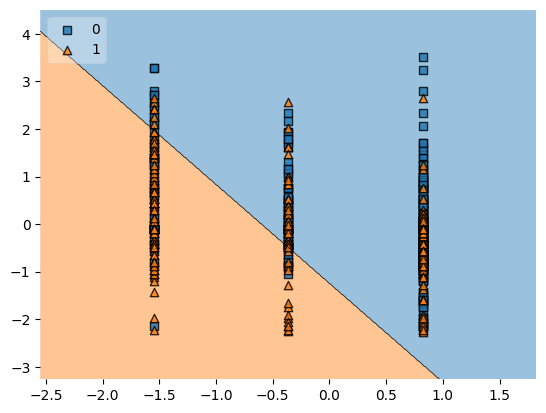

In [159]:
#to get decision boundary of the model
from sklearn.preprocessing import LabelEncoder
from mlxtend.plotting import plot_decision_regions
le = LabelEncoder()
Y_train_encoded = le.fit_transform(Y_train)
# Select the first two features
X_train_2d = X_train[:, :2]

clf_2d = LogisticRegression()
clf_2d.fit(X_train_2d, Y_train_encoded)

plot_decision_regions(
    X_train_2d,
    Y_train_encoded,
    clf=clf_2d,
    legend=2
)